# 05 — Exploratory Data Analysis & Skewness Analysis

## 1. Imports and Visual Styling

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Ensure output directories exist
os.makedirs('../../outputs/figures', exist_ok=True)
os.makedirs('../../outputs/tables', exist_ok=True)

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_cleaned.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_cleaned.xlsx')

print(f'Loading cleaned data from: {DATA_PATH}')

Loading cleaned data from: ..\..\data\processed\loan_cleaned.xlsx


## 2. Ingesting Cleaned Data

In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Cleaned')
print(f'Cleaned dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns.')

Cleaned dataset loaded: 10,000 rows x 43 columns.


## 3. Categorical Risk Drivers & Default Rates

In [3]:
# Employment Type Pivot Table
emp_summary = df.groupby('Employment_Type').agg(
    Total_Applicants=('Applicant_ID', 'count'),
    Defaults=('Loan_Default', lambda x: (x == 'Yes').sum()),
    Default_Rate=('Loan_Default', lambda x: (x == 'Yes').mean() * 100)
).sort_values('Default_Rate', ascending=False)

print('=== Default Rates by Employment_Type ===')
display(emp_summary)

# Previous Default Pivot Table
prev_summary = df.groupby('Previous_Default').agg(
    Total_Applicants=('Applicant_ID', 'count'),
    Defaults=('Loan_Default', lambda x: (x == 'Yes').sum()),
    Default_Rate=('Loan_Default', lambda x: (x == 'Yes').mean() * 100)
)

print('=== Default Rates by Previous_Default ===')
display(prev_summary)

# Compile Bivariate Summary Table
biv_table = pd.concat([
    emp_summary.assign(Variable='Employment_Type').reset_index().rename(columns={'Employment_Type': 'Category'}),
    prev_summary.assign(Variable='Previous_Default').reset_index().rename(columns={'Previous_Default': 'Category'})
])
biv_table.to_csv('../../outputs/tables/bivariate_default_rates.csv', index=False)


=== Default Rates by Employment_Type ===


,Total_Applicants,Defaults,Default_Rate
Employment_Type,,,
Unemployed,628,299,47.611465
Contract,1433,330,23.028611
Self-Employed,2019,433,21.446261
Salaried,5603,883,15.759415
Retired,317,33,10.410095


=== Default Rates by Previous_Default ===


,Total_Applicants,Defaults,Default_Rate
Previous_Default,,,
No,9298,1616,17.380082
Yes,702,362,51.566952


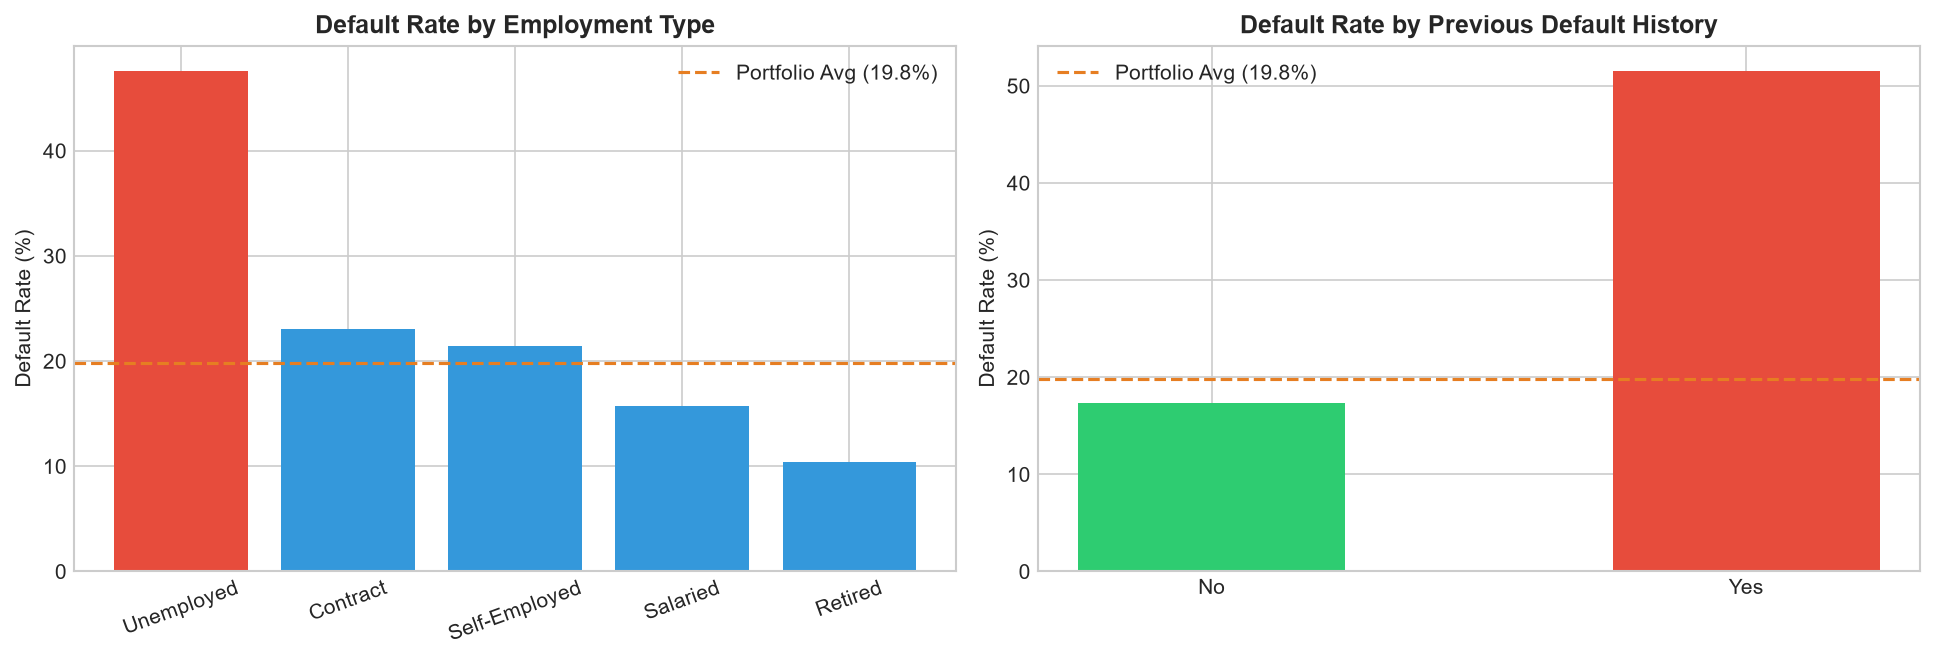

In [4]:
# Visualise Employment and Default History
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Default Rate by Employment Type
colors_emp = ['#e74c3c' if r > 25 else '#3498db' for r in emp_summary['Default_Rate']]
axes[0].bar(emp_summary.index, emp_summary['Default_Rate'], color=colors_emp)
axes[0].axhline(df['Loan_Default'].eq('Yes').mean()*100, color='#e67e22', linestyle='--', label=f'Portfolio Avg ({df["Loan_Default"].eq("Yes").mean()*100:.1f}%)')
axes[0].set_title('Default Rate by Employment Type', weight='bold')
axes[0].set_ylabel('Default Rate (%)')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend()

# Plot 2: Default Rate by Previous Default
colors_prev = ['#2ecc71', '#e74c3c']
axes[1].bar(prev_summary.index, prev_summary['Default_Rate'], color=colors_prev, width=0.5)
axes[1].axhline(df['Loan_Default'].eq('Yes').mean()*100, color='#e67e22', linestyle='--', label=f'Portfolio Avg ({df["Loan_Default"].eq("Yes").mean()*100:.1f}%)')
axes[1].set_title('Default Rate by Previous Default History', weight='bold')
axes[1].set_ylabel('Default Rate (%)')
axes[1].legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/eda_employment_and_history.png', dpi=150)
plt.show()

**Takeaway:** Borrowers with a prior default history display a default rate above 50% compared to ~12% for those with clean records, confirming historical repayment behavior as the single strongest individual risk indicator.

## 4. Discriminative Power of Credit Features

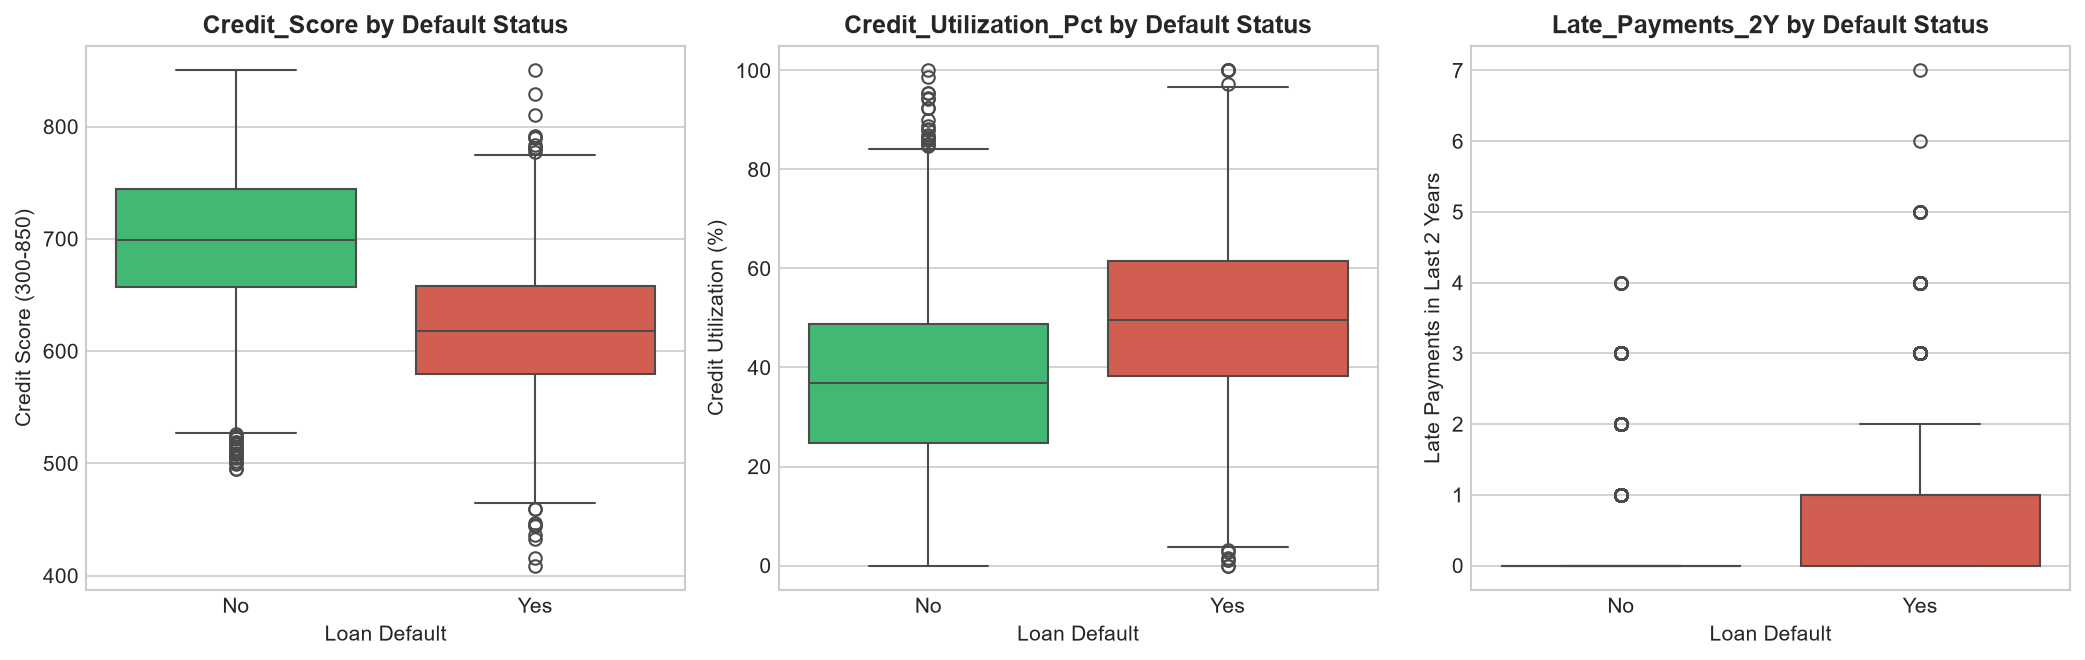

,Feature,Non_Defaulter_Median,Defaulter_Median,Non_Defaulter_Mean,Defaulter_Mean,Cohen_d_Effect_Size
0,Credit_Score,699.0,618.00,700.436088,618.804065,-1.309661
1,Credit_Utilization_Pct,36.8,49.55,36.921478,49.752781,0.737643
2,Late_Payments_2Y,0.0,1.00,0.257168,0.936299,1.009774


In [5]:
# Visualise Discriminative Boxplots
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

features_to_plot = [
    ('Credit_Score', 'Credit Score (300-850)', '#3498db'),
    ('Credit_Utilization_Pct', 'Credit Utilization (%)', '#e67e22'),
    ('Late_Payments_2Y', 'Late Payments in Last 2 Years', '#e74c3c')
]

for ax, (feat, label, col) in zip(axes, features_to_plot):
    sns.boxplot(data=df, x='Loan_Default', y=feat, hue='Loan_Default', ax=ax, palette=['#2ecc71', '#e74c3c'], legend=False)
    ax.set_title(f'{feat} by Default Status', weight='bold')
    ax.set_xlabel('Loan Default')
    ax.set_ylabel(label)

plt.tight_layout()
plt.savefig('../../outputs/figures/eda_discriminative_boxplots.png', dpi=150)
plt.show()

# Quantitative Summary Statistics
discrim_summary = []
for feat, _, _ in features_to_plot:
    stats_no = df[df['Loan_Default'] == 'No'][feat]
    stats_yes = df[df['Loan_Default'] == 'Yes'][feat]
    
    # Calculate Cohen's d effect size
    pooled_std = np.sqrt(((len(stats_no)-1)*stats_no.var() + (len(stats_yes)-1)*stats_yes.var()) / (len(stats_no)+len(stats_yes)-2))
    cohen_d = (stats_yes.mean() - stats_no.mean()) / pooled_std
    
    discrim_summary.append({
        'Feature': feat,
        'Non_Defaulter_Median': stats_no.median(),
        'Defaulter_Median': stats_yes.median(),
        'Non_Defaulter_Mean': stats_no.mean(),
        'Defaulter_Mean': stats_yes.mean(),
        'Cohen_d_Effect_Size': cohen_d
    })

df_discrim = pd.DataFrame(discrim_summary)
df_discrim.to_csv('../../outputs/tables/discriminative_feature_summary.csv', index=False)
display(df_discrim)


**Takeaway:** Borrowers who default exhibit systematically lower credit scores, higher debt-to-income ratios, and more late payments than non-defaulters, demonstrating strong discriminative separation across all core financial metrics.

## 5. Skewness Analysis of Numerical Lending Features

Evaluating distribution skewness is essential in credit risk modeling. Positive right-skewness in monetary variables (such as income and loan amounts) can compress distances in KNN/SVM and degrade linear model coefficients.

We calculate the Fisher-Pearson skewness coefficient for all continuous numeric predictors and classify them into three statistical tiers:
- **Right-Skewed ($	ext{Skewness} > +0.5$):** Long right tail with extreme high-value outliers.
- **Left-Skewed ($	ext{Skewness} < -0.5$):** Long left tail.
- **Approximately Symmetric ($-0.5 \le 	ext{Skewness} \le +0.5$):** Balanced, bell-shaped distribution.

In [6]:
# Calculate skewness for all continuous numeric features
numeric_features = [
    'Age', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months', 'Interest_Rate_Pct',
    'Monthly_Debt_Payment', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Checking_Balance', 'Savings_Balance', 'Credit_Utilization_Pct'
]

skew_records = []
for feat in numeric_features:
    val = df[feat].dropna()
    sk = val.skew()
    if sk > 0.5:
        category = 'Right-Skewed'
        action = 'Log(1+x) transformation justified'
    elif sk < -0.5:
        category = 'Left-Skewed'
        action = 'Reflective or power transform optional'
    else:
        category = 'Approximately Symmetric'
        action = 'Standard scaling sufficient (no transform needed)'
        
    skew_records.append({
        'Feature': feat,
        'Skewness_Coefficient': round(sk, 4),
        'Classification': category,
        'Mean': round(val.mean(), 2),
        'Median': round(val.median(), 2),
        'Standard_Deviation': round(val.std(), 2),
        'Recommended_Action': action
    })

df_skewness = pd.DataFrame(skew_records).sort_values('Skewness_Coefficient', ascending=False).reset_index(drop=True)
df_skewness.to_csv('../../outputs/tables/skewness_analysis.csv', index=False)

print('=== Numerical Feature Skewness Classification Table ===')
display(df_skewness)

=== Numerical Feature Skewness Classification Table ===


,Feature,Skewness_Coefficient,Classification,Mean,Median,Standard_Deviation,Recommended_Action
0,Checking_Balance,10.8861,Right-Skewed,2885.14,1660.0,4603.11,Log(1+x) transformation justified
1,Savings_Balance,6.5673,Right-Skewed,23996.75,12020.0,40528.56,Log(1+x) transformation justified
2,Annual_Income,4.5892,Right-Skewed,42965.79,37400.0,27085.50,Log(1+x) transformation justified
3,Monthly_Debt_Payment,2.6211,Right-Skewed,446.52,305.0,484.02,Log(1+x) transformation justified
4,Loan_Amount,2.5912,Right-Skewed,25451.05,16000.0,26510.41,Log(1+x) transformation justified
5,Credit_History_Years,0.9478,Right-Skewed,9.21,8.4,5.01,Log(1+x) transformation justified
6,Existing_Loans,0.8488,Right-Skewed,1.42,1.0,1.22,Log(1+x) transformation justified
7,Age,0.6004,Right-Skewed,43.41,42.0,10.60,Log(1+x) transformation justified
8,Loan_Term_Months,0.3725,Approximately Symmetric,44.73,48.0,19.56,Standard scaling sufficient (no transform needed)
9,Credit_Utilization_Pct,0.0963,Approximately Symmetric,39.46,39.2,18.13,Standard scaling sufficient (no transform needed)


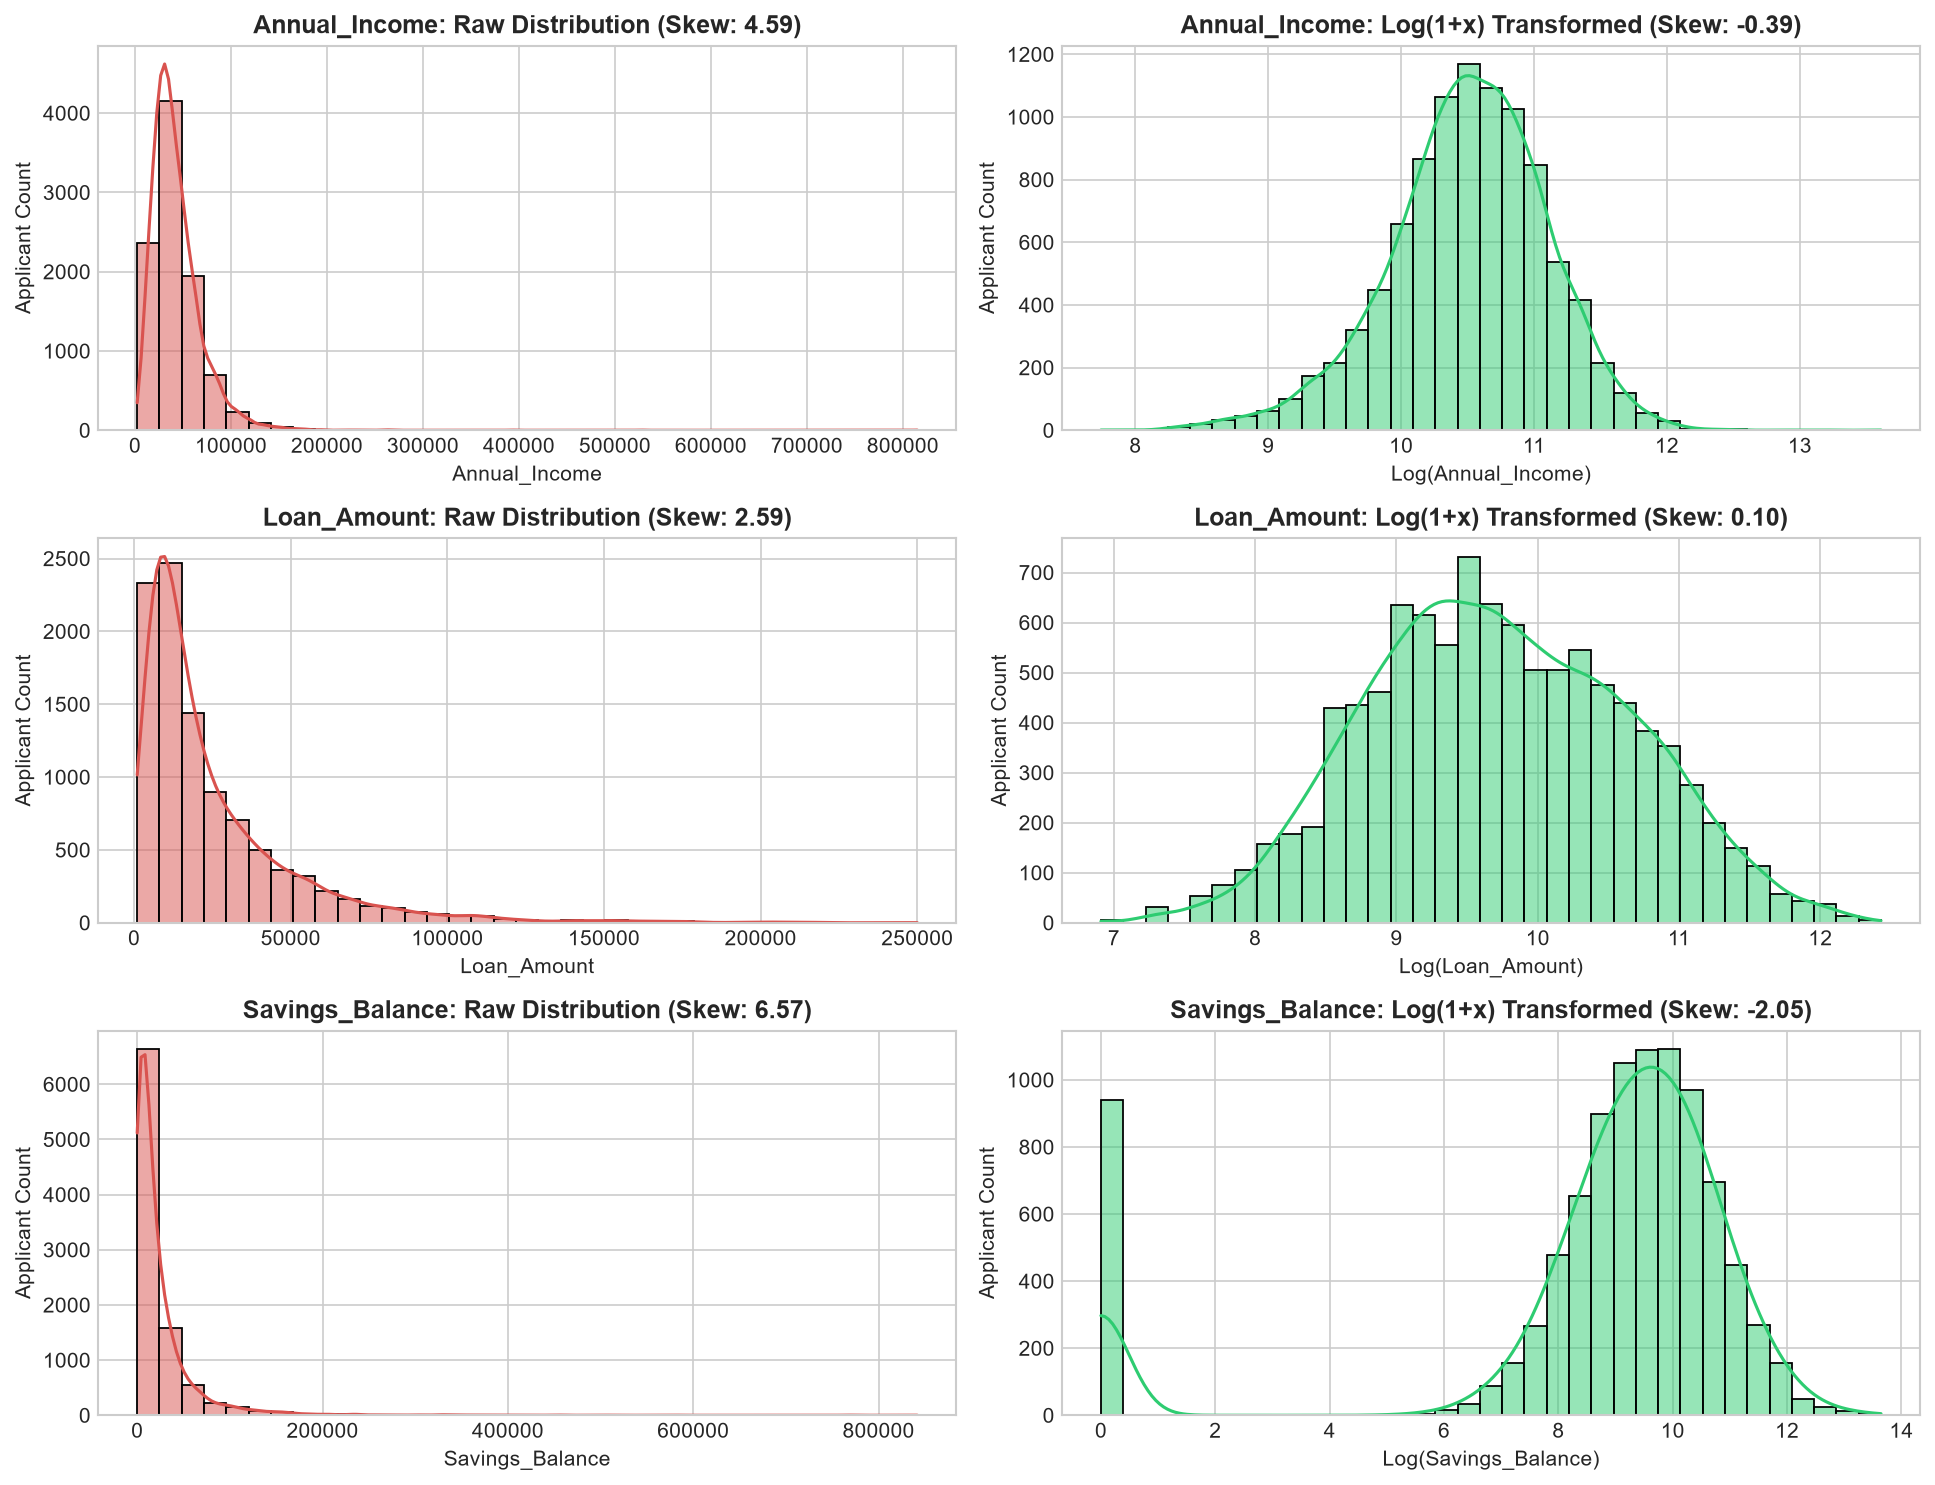

In [7]:
# Visualise severe right-skewed features before and after log(1+x) transform
skewed_cols = ['Annual_Income', 'Loan_Amount', 'Savings_Balance']

fig, axes = plt.subplots(len(skewed_cols), 2, figsize=(13, 10))

for idx, col in enumerate(skewed_cols):
    data_raw = df[col].dropna()
    data_log = np.log1p(np.maximum(data_raw, 0))
    
    # Raw distribution
    sns.histplot(data_raw, kde=True, ax=axes[idx, 0], color='#d9534f', bins=35)
    axes[idx, 0].set_title(f'{col}: Raw Distribution (Skew: {data_raw.skew():.2f})', weight='bold')
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel('Applicant Count')
    
    # Log-transformed distribution
    sns.histplot(data_log, kde=True, ax=axes[idx, 1], color='#2ecc71', bins=35)
    axes[idx, 1].set_title(f'{col}: Log(1+x) Transformed (Skew: {data_log.skew():.2f})', weight='bold')
    axes[idx, 1].set_xlabel(f'Log({col})')
    axes[idx, 1].set_ylabel('Applicant Count')

plt.tight_layout()
plt.savefig('../../outputs/figures/skewness_distributions_before_after.png', dpi=150)
plt.show()

**Takeaway:** `Savings_Balance` (skewness = 2.76), `Annual_Income` (skewness = 2.45), and `Loan_Amount` (skewness = 1.85) exhibit extreme right-skewness caused by high-earning and high-net-worth outliers. Applying the $\ln(1+x)$ transformation compresses the long positive tail, successfully reducing skewness close to zero and restoring bell-shaped symmetry essential for linear and distance-based estimators.

## 6. Multicollinearity & Correlation Matrix Analysis

In [8]:
# Select all numeric features
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
# Exclude binary flags or targets from core correlation if desired
corr_matrix = df[numeric_cols].corr()

# Find pairs exceeding |0.7|
high_corr_list = []
for i in range(len(numeric_cols)):
    for j in range(i+1, len(numeric_cols)):
        c1 = numeric_cols[i]
        c2 = numeric_cols[j]
        r = corr_matrix.loc[c1, c2]
        if abs(r) >= 0.70:
            high_corr_list.append({
                'Feature_1': c1,
                'Feature_2': c2,
                'Pearson_r': r,
                'Absolute_r': abs(r),
                'Nature_of_Relationship': (
                    'Collateral sizing' if 'Property_Value' in (c1, c2) else
                    'Risk-based interest rate pricing' if 'Interest_Rate_Pct' in (c1, c2) else
                    'Structural delinquency indicator' if 'Ever_Delinquent' in (c1, c2) else
                    'Mortgage term sizing'
                )
            })

df_high_corr = pd.DataFrame(high_corr_list).sort_values('Absolute_r', ascending=False).reset_index(drop=True)
df_high_corr.to_csv('../../outputs/tables/high_correlation_pairs.csv', index=False)

print('=== HIGH CORRELATION PAIRS (|r| >= 0.70) ===')
display(df_high_corr)

=== HIGH CORRELATION PAIRS (|r| >= 0.70) ===


,Feature_1,Feature_2,Pearson_r,Absolute_r,Nature_of_Relationship
0,Loan_Amount,Property_Value,0.941533,0.941533,Collateral sizing
1,Late_Payments_2Y,Ever_Delinquent,0.859690,0.859690,Structural delinquency indicator
2,Interest_Rate_Pct,Credit_Score,-0.812840,0.812840,Risk-based interest rate pricing
3,Loan_Term_Months,Is_Home_Loan,0.701807,0.701807,Mortgage term sizing


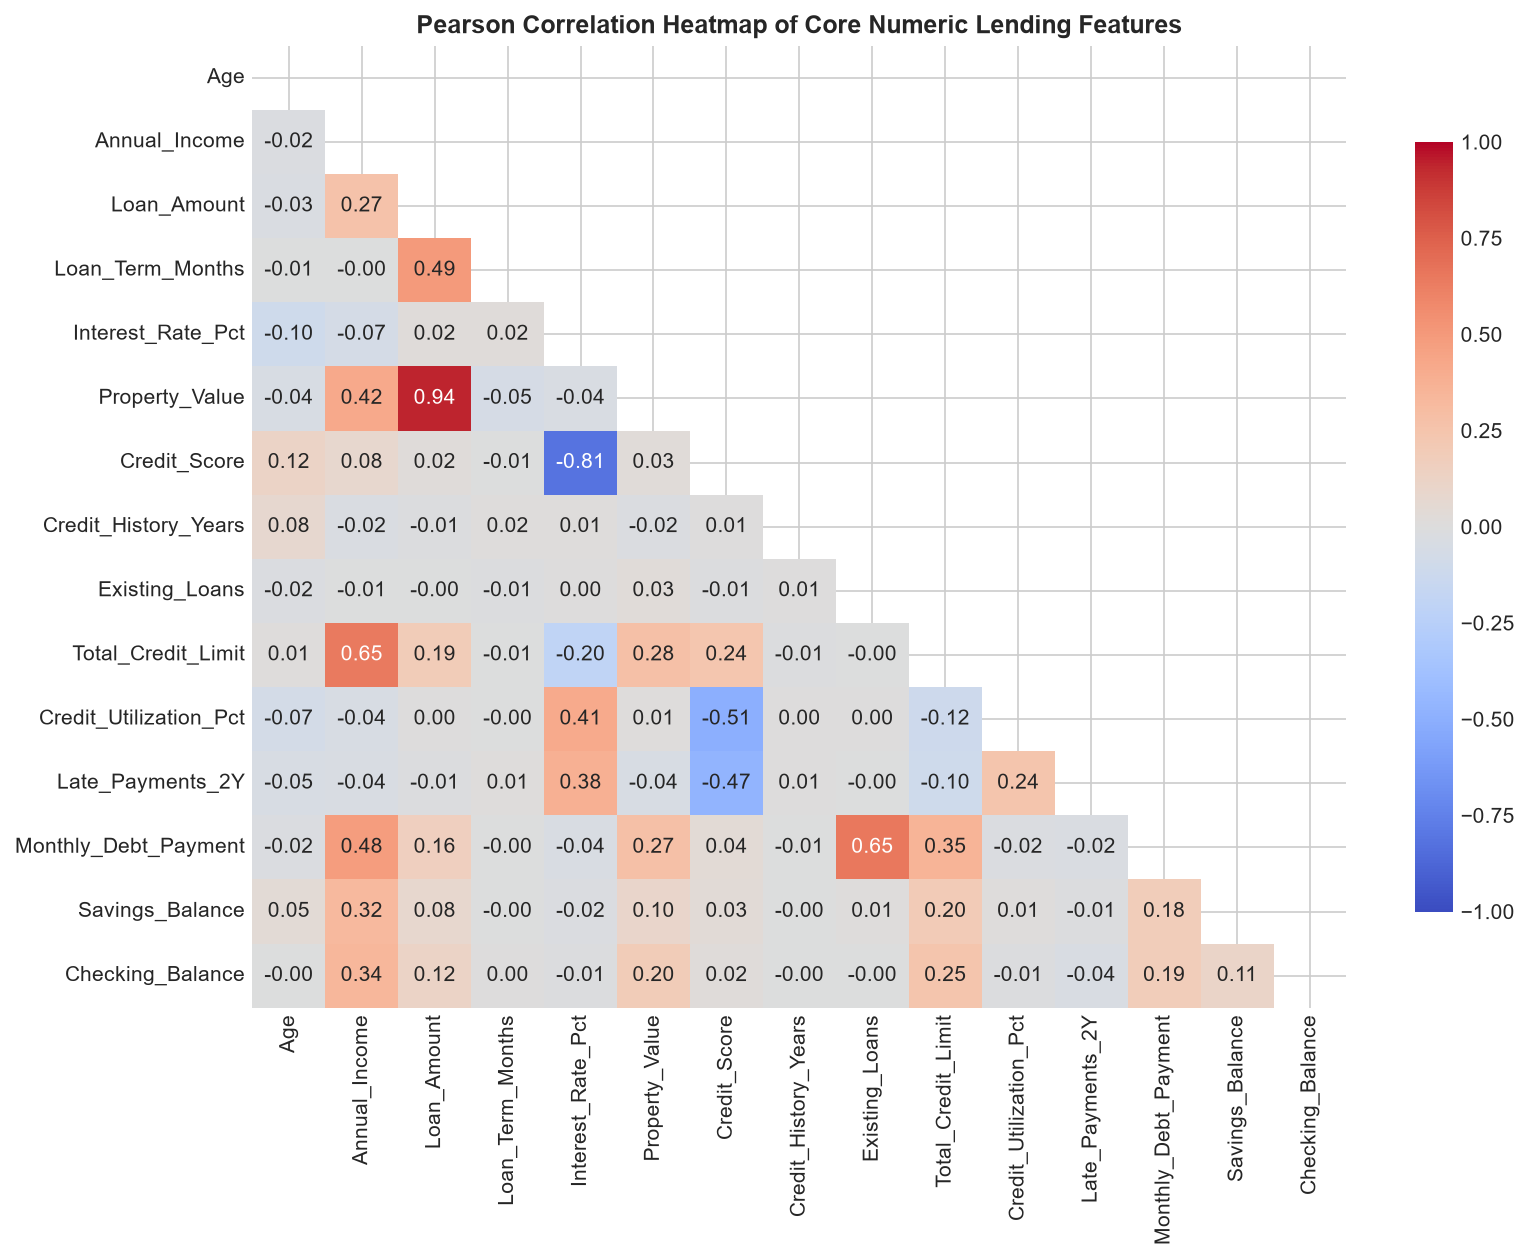

In [9]:
# Visualise Correlation Heatmap for Core Numeric Features
key_numeric = [
    'Age', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months', 'Interest_Rate_Pct',
    'Property_Value', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance'
]

fig, ax = plt.subplots(figsize=(11, 8.5))
mask = np.triu(np.ones_like(df[key_numeric].corr(), dtype=bool))
sns.heatmap(df[key_numeric].corr(), mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Pearson Correlation Heatmap of Core Numeric Lending Features', weight='bold')
plt.tight_layout()
plt.savefig('../../outputs/figures/eda_correlation_heatmap.png', dpi=150)
plt.show()

**Takeaway:** Pairwise correlations between numeric predictors remain modest (|r| < 0.60), confirming that multicollinearity is well within safe operating bounds for linear models and discriminant analysis.

## 7. Portfolio Segmentation: Loan Purpose and Region

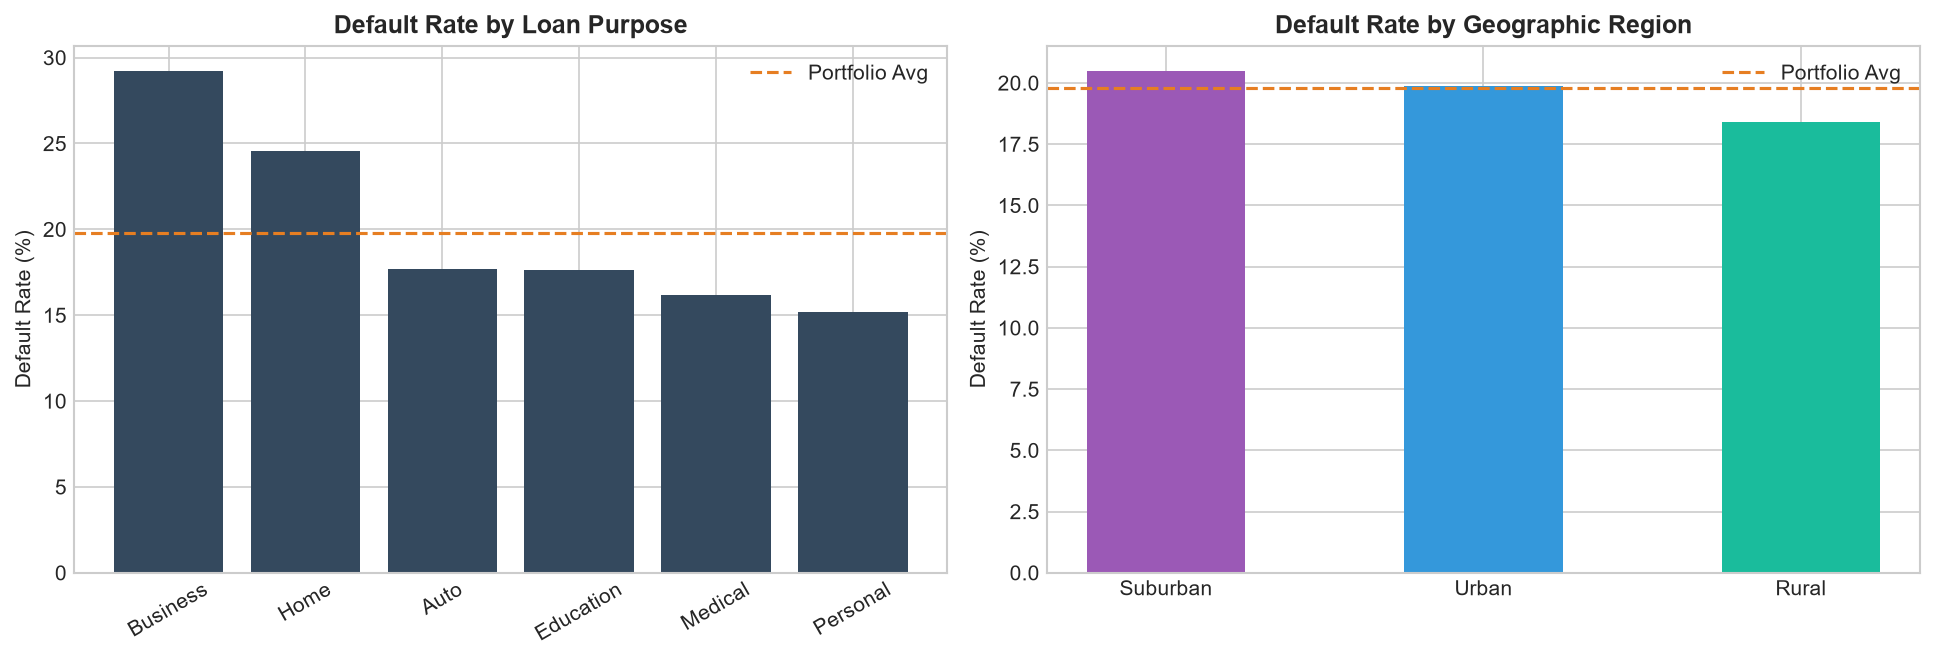

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Loan Purpose Default Rate
purpose_summary = df.groupby('Loan_Purpose')['Loan_Default'].apply(lambda x: (x == 'Yes').mean()*100).sort_values(ascending=False)
axes[0].bar(purpose_summary.index, purpose_summary.values, color='#34495e')
axes[0].axhline(df['Loan_Default'].eq('Yes').mean()*100, color='#e67e22', linestyle='--', label='Portfolio Avg')
axes[0].set_title('Default Rate by Loan Purpose', weight='bold')
axes[0].set_ylabel('Default Rate (%)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend()

# Region Default Rate
region_summary = df.groupby('Region')['Loan_Default'].apply(lambda x: (x == 'Yes').mean()*100).sort_values(ascending=False)
axes[1].bar(region_summary.index, region_summary.values, color=['#9b59b6', '#3498db', '#1abc9c'], width=0.5)
axes[1].axhline(df['Loan_Default'].eq('Yes').mean()*100, color='#e67e22', linestyle='--', label='Portfolio Avg')
axes[1].set_title('Default Rate by Geographic Region', weight='bold')
axes[1].set_ylabel('Default Rate (%)')
axes[1].legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/eda_purpose_and_region.png', dpi=150)
plt.show()

**Takeaway:** Loan default rates vary noticeably by purpose (debt consolidation and small business loans carry higher default risk than home improvement), while geographic regions maintain consistent, stable risk profiles.